# 위고비 시장 확산이 기존 사망보험금에 미치는 영향

**SELECT 전체 사망 근거 × 10년 기존 생명보험 정기 사망보장 조건부 모형**

이 노트북은 **SELECT 유사 고위험 가상 가입자 1,000명**에서 위고비 연간 최초 시작확률이 1%에서 3%로 높아지는 시장 확산 시나리오를 비교한다. 보험기간 10년 동안의 기대 사망과 기존 사망보험금 현가가 얼마나 달라지는지 계산한다.

> `시장 저확산 → 고확산`은 위고비 시장 전체 확산 효과다. 약제비 특약의 귀속효과를 계산할 때에는 별도로 추정한 `특약 없음 A → 특약 있음 A+B`의 시작경로 차이를 사용해야 한다.


## 1. 임상 근거와 적용 대상

| 항목 | SELECT 결과 | 이번 분석의 처리 |
|---|---:|---|
| 대상 | 45세 이상, BMI 27 이상, 기존 심혈관질환, 비당뇨 | **SELECT 유사 고위험 가상 가입자**로 적용 범위를 한정 |
| 전체 사망 | HR 0.81 (95% CI 0.71~0.93) | 최초 치료 시작 후 36개월의 사망강도에 적용 |
| 위약군 사망 | 458건 / 29,112인년 | 기초 사망강도 $\mu_0$ 계산 |
| 평균 추적기간 | 39.8개월 | 10년 계약으로 외삽할 때의 한계로 반영 |

전체 사망 결과는 SELECT의 위계검정 체계에서 탐색적 결과다. 대상자 구성도 국내 생명보험 가입자와 같지 않으므로 HR=1 무효과를 민감도에 포함한다.

**출처**

- Lincoff et al. *Semaglutide and Cardiovascular Outcomes in Obesity without Diabetes*. NEJM 2023. https://doi.org/10.1056/NEJMoa2307563
- SELECT 검토자료 Table 19. https://www.ncbi.nlm.nih.gov/books/NBK619926/table/tr8269868382084182_ch01_t19/?report=objectonly


## 2. 가상 사망보장 계약과 계산 조건

| 구분 | 기준값 | 의미 |
|---|---:|---|
| 가상 가입자 | 1,000명 | SELECT 유사 고위험 가상 가입자 |
| 기존 보장 | 정기 사망보장 | 기존 생명보험 계약의 기대 급부 분석 |
| 사망보험금 | 계약당 1억 원 | 사망 시 1회 지급 |
| 보험기간 | 10년 | 120개월 월별 추적 |
| 시장 저확산·고확산 | 연 1%·3% | 생존·미시작자 기준 최초 시작확률 |
| 효과 적용기간 | 최초 시작 후 36개월 | 연구팀의 시나리오 가정 |
| 할인율 | 연 3% | 월중앙 지급 가정의 현재가치 계산 |
| 기초 사망강도 | 458 / 29,112인년 | SELECT 위약군 기간 평균의 일정 강도 근사 |

보험금액 자체는 변하지 않는다. 시장 확산에 따라 사망 가능성과 시점이 달라질 때의 **기대 사망보험금 감소**를 계산한다. 해지, 연령 증가에 따른 기초위험 변화와 계약조건 변경은 반영하지 않는다.


In [1]:
from IPython.display import display, Image
from pathlib import Path
from PIL import Image as PILImage
# 그림은 노트북에서 수식·데이터로 다시 그리며, 별도 파일이 없어도 재현됩니다.

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from matplotlib import font_manager

fontset={f.name for f in font_manager.fontManager.ttflist}
for ff in ['Arial Unicode MS','AppleGothic','NanumSquare','Noto Sans CJK KR','Malgun Gothic','NanumGothic']:
    if ff in fontset:
        plt.rcParams['font.family']=ff
        break
plt.rcParams.update({'axes.unicode_minus':False,'axes.spines.top':False,'axes.spines.right':False,'axes.titlesize':13,'font.size':10})
BLUE='#2563A6'; GREEN='#0B8A7A'; GREY='#66778E'; ORANGE='#D47A31'

# 관측/논문값과 연구자 설정을 구분
SELECT_PLACEBO_DEATHS=458
SELECT_PLACEBO_PERSON_YEARS=29112
MU=SELECT_PLACEBO_DEATHS/SELECT_PLACEBO_PERSON_YEARS # 평균 발생률의 일정 사망강도 근사
TRIAL_HR=0.81 # SELECT 탐색적, 한국에서 효과를 검증한 값 아님
COHORT=1000 # SELECT 유사 기존 가입자의 가상 인원
BENEFIT=100_000_000 # 원/사망, 가상 계약
TERM=10 # 년
ANNUAL_DISCOUNT=0.03 # 가상 계약 평가 이율
EFFECT_MONTHS=36 # 시작 후 효과 창, 과학적으로 확정된 약효 만료일 아님
LOW_START=.01 # 국내 실증 시작률 아님
HIGH_START=.03 # 국내 실증 시작률 아님

print('위약군 평균 연 사망강도:', round(MU,8),'(년^-1)')
print('일정강도 가정의 연 사망확률:',round((1-math.exp(-MU))*100,4),'%')
print('치료 시작 전의 한 달 사망확률:',round((1-math.exp(-MU/12))*100,4),'%')
print('치료효과 적용 중 한 달 사망확률:',round((1-math.exp(-MU*TRIAL_HR/12))*100,4),'%')

Matplotlib is building the font cache; this may take a moment.


위약군 평균 연 사망강도: 0.01573234 (년^-1)
일정강도 가정의 연 사망확률: 1.5609 %
치료 시작 전의 한 달 사망확률: 0.131 %
치료효과 적용 중 한 달 사망확률: 0.1061 %


## 3. 치료 시작경로와 사망효과 적용 방법

최초에는 모두 생존·미시작 상태다. 연 시작확률 $a$는 생존·미시작자를 분모로 하는 월 확률로 변환한다.

$$
p_{\mathrm{start},m}=1-(1-a)^{1/12}
$$

위약군 사망 건수와 관찰 인년에서 기초 사망강도를 계산하고, 치료 시작 후 36개월에는 HR 0.81을 적용한다. 효과기간이 끝난 뒤에는 HR 1로 되돌린다.

$$
\mu_0=\frac{458}{29{,}112}, \qquad
p_{\mathrm{death},m}=1-\exp\left(-\mu_0\times HR_m/12\right)
$$

HR은 연 사망확률에 직접 곱하지 않고 사망강도에 적용한다. 연 1%·3%는 국내 실측 시작률이 아니라 시장 저확산·고확산을 비교하기 위한 연구 가정이다. CBO의 비만치료제 보장확대 전망은 3% 조건의 외부 참고일 뿐 국내 값을 입증하지 않는다.

**참고 출처:** CBO, *How Would Authorizing Medicare to Cover Anti-Obesity Medications Affect the Federal Budget?* 2024. https://www.cbo.gov/publication/60816


## 4. 월별 코호트 및 기대 사망보험금 계산

매월 다음 순서로 코호트를 이동한다.

1. 생존·미시작자에서 신규 시작자를 분리한다.
2. 미시작자와 시작월별 코호트에 각각의 월 사망확률을 적용한다.
3. 사망자를 제외한 생존자만 다음 달로 넘긴다.
4. 월 기대 사망 건수에 계약당 1억 원을 곱한다.
5. 월중앙 지급을 가정해 연 3%로 할인하고 120개월을 합산한다.

$$
PV_{\mathrm{claim}}
=\sum_{m=1}^{120}
\frac{E[D_m]\times100{,}000{,}000}{1.03^{(m-0.5)/12}}
$$

$D_m$은 $m$월의 기대 사망 건수다. 치료 시작은 월초, 사망보험금 지급은 월중앙으로 근사한다. 시작월별 코호트를 분리해 36개월 효과기간이 지난 계약은 자동으로 HR 1을 적용한다.


In [3]:
# 월별 생존·사망·첫 치료 시작을 직접 추적하는 함수
N_YEARS=10
DEATH_BENEFIT=BENEFIT
def project(annual_start,hr=.81,effect_m=36,mu=MU,discount=.03,cohort=1000,years=10):
    n_months=years*12
    never_started=float(cohort)
    active=[0.]*n_months
    first_start_prob= -math.expm1(math.log1p(-annual_start)/12)
    rows=[]
    total_started=0.; total_deaths=0.; total_pv=0.
    for m in range(n_months):
        survival_start=never_started + sum(active)
        new = never_started*first_start_prob
        never_started -= new
        active[m] += new
        total_started+=new
        death_never=never_started * -math.expm1(-mu/12)
        death_started=0.
        for j in range(m+1):
            age=m-j
            mult=hr if age<effect_m else 1.
            dq= -math.expm1(-mu*mult/12)
            d=active[j]*dq
            active[j]-=d
            death_started+=d
        never_started-=death_never
        monthly_death=death_never+death_started
        total_deaths+=monthly_death
        pv=monthly_death*DEATH_BENEFIT/(1+discount)**((m+.5)/12)
        total_pv+=pv
        alive_end=never_started+sum(active)
        assert abs(survival_start-(monthly_death+alive_end)) < 1e-7 * max(1,cohort)
        rows.append({'월':m+1,'연도':m//12+1,'최초_시작':new,'누적_시작':total_started,
                     '월_기대사망':monthly_death,'누적_기대사망':total_deaths,'월_보험금_현가_원':pv,
                     '누적_보험금_현가_원':total_pv,'미시작_생존':never_started,
                     '시작경험_생존':sum(active),'전체_생존':alive_end})
    d=pd.DataFrame(rows)
    return {'n':cohort,'annual_start':annual_start,'hr':hr,'duration_months':effect_m,'mu':mu,
            'discount':discount,'starts':total_started,'deaths':total_deaths,'survivors':cohort-total_deaths,
            'pv':total_pv,'nominal':total_deaths*DEATH_BENEFIT,'monthly':d}


def contrast(hr=.81,effect_m=36,mu=MU,discount=.03,low=.01,high=.03,n=1000):
    kw=dict(hr=hr,effect_m=effect_m,mu=mu,discount=discount,cohort=n)
    L=project(low,**kw);H=project(high,**kw)
    return {'low':L,'high':H,'delta_starts':H['starts']-L['starts'],
            'avoided_deaths':L['deaths']-H['deaths'],'pv_saving':L['pv']-H['pv'],
            'nominal_saving':L['nominal']-H['nominal']}

## 5. 기준 결과

시장 저확산(연 1%)과 고확산(연 3%)을 동일한 계약·사망효과 가정에서 비교한다. 기대 사망은 확정된 실제 사망 건수가 아니라 코호트 기대값이다.


In [4]:
base=contrast()
base_table=pd.DataFrame({
    '항목':['10년 누적 첫 시작 (명)','10년 기대 사망 (건)','10년 사망보험금 명목액 (억 원)','10년 사망보험금 현가 (억 원)'],
    '저확산 연 1%':[base['low']['starts'],base['low']['deaths'],base['low']['nominal']/1e8,base['low']['pv']/1e8],
    '고확산 연 3%':[base['high']['starts'],base['high']['deaths'],base['high']['nominal']/1e8,base['high']['pv']/1e8]
})
base_table['차이(고확산-저확산)']=base_table['고확산 연 3%']-base_table['저확산 연 1%']
display(base_table.round(4))
print(f"기대 사망 감소: {base['avoided_deaths']:.4f}건")
print(f"보험금 PV 감소: {base['pv_saving']:,.0f}원 = {base['pv_saving']/1e8:.4f}억 원")
assert abs(base['pv_saving']-96961864)<5
assert abs(base['low']['deaths']-144.94)<.1
assert abs(base['high']['deaths']-143.81)<.1

,항목,저확산 연 1%,고확산 연 3%,차이(고확산-저확산)
0,10년 누적 첫 시작 (명),88.6505,244.0920,155.4416
1,10년 기대 사망 (건),144.9396,143.8117,-1.1279
2,10년 사망보험금 명목액 (억 원),144.9396,143.8117,-1.1279
3,10년 사망보험금 현가 (억 원),125.9768,125.0072,-0.9696


기대 사망 감소: 1.1279건
보험금 PV 감소: 96,961,864원 = 0.9696억 원


## 주요 결과 시각화


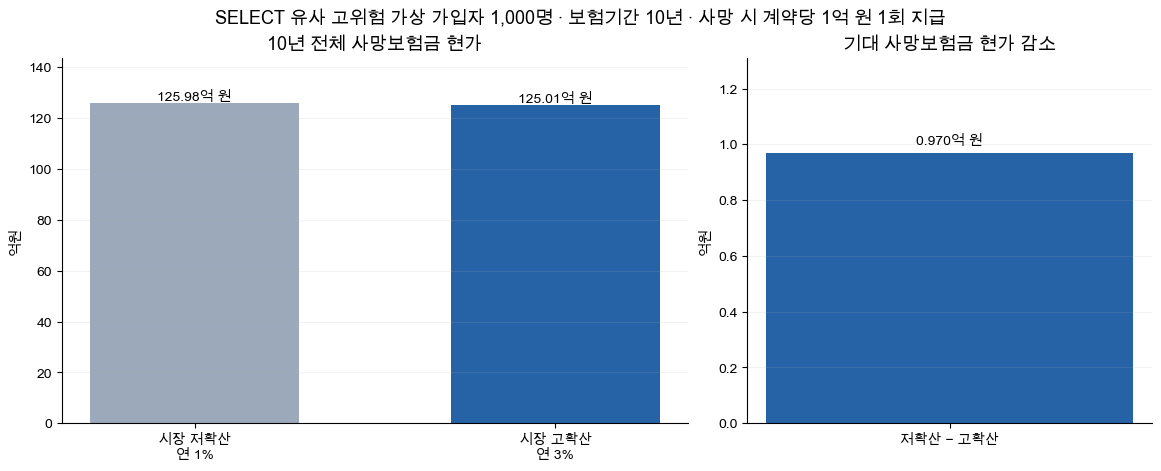

In [5]:
low_pv_eok = base['low']['pv'] / 1e8
high_pv_eok = base['high']['pv'] / 1e8
pv_reduction_eok = base['pv_saving'] / 1e8

fig, axes = plt.subplots(
    1, 2, figsize=(11.5, 4.6), layout='constrained',
    gridspec_kw={'width_ratios': [1.55, 1]}
)

scenario_labels = ['시장 저확산\n연 1%', '시장 고확산\n연 3%']
scenario_values = [low_pv_eok, high_pv_eok]
bars = axes[0].bar(scenario_labels, scenario_values,
                   color=['#9BA9BA', BLUE], width=.58)
axes[0].set(title='10년 전체 사망보험금 현가', ylabel='억원')
axes[0].set_ylim(0, max(scenario_values) * 1.14)
axes[0].grid(axis='y', alpha=.16)
for bar, value in zip(bars, scenario_values):
    axes[0].text(bar.get_x() + bar.get_width()/2, value,
                 f'{value:,.2f}억 원', ha='center', va='bottom', weight='bold')

diff_bar = axes[1].bar(['저확산 − 고확산'], [pv_reduction_eok],
                       color=BLUE, width=.52)
axes[1].set(title='기대 사망보험금 현가 감소', ylabel='억원')
axes[1].set_ylim(0, pv_reduction_eok * 1.35)
axes[1].grid(axis='y', alpha=.16)
axes[1].bar_label(diff_bar, labels=[f'{pv_reduction_eok:,.3f}억 원'],
                  padding=4, weight='bold')

fig.suptitle(
    f'SELECT 유사 고위험 가상 가입자 {COHORT:,}명 · 보험기간 {N_YEARS}년 · '
    f'사망 시 계약당 {DEATH_BENEFIT/1e8:.0f}억 원 1회 지급',
    fontsize=13, weight='bold'
)
plt.show()


시장 고확산에서는 저확산보다 10년 기대 사망보험금 현가가 감소한다. 왼쪽은 두 경로의 전체 현가, 오른쪽은 그 차이를 분리해 보여준다.  이 차이는 시장 전체 확산 효과이며 약제비 특약 귀속효과가 아니다.


고확산 경로에서는 10년 누적 최초 시작자가 약 155.44명 늘고, 기대 사망은 약 **1.1279건** 감소한다. 이에 따른 기대 사망보험금 현가 감소는 약 **9,696만 원**이다. 사망 시 계약당 지급하는 1억 원은 동일하며 지급 가능성과 시점만 달라진다.


### 5-1. 연도별 경로와 누적 변화

연도별 기대 사망, 기대 사망보험금 현가와 누적 최초 시작자 경로를 확인한다.


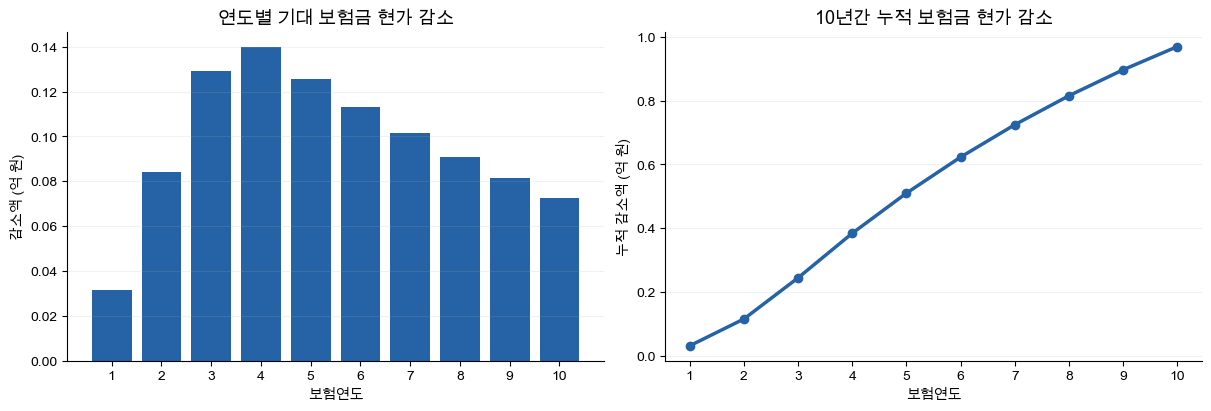

In [6]:
# 그래프 1. 같은 집단의 10년 변화: 연간 감소액과 누적 감소액
L=base['low']['monthly']; H=base['high']['monthly']
annual=pd.DataFrame([{'연도':y,
 '저확산_사망':L.loc[L['연도']==y,'월_기대사망'].sum(),
 '고확산_사망':H.loc[H['연도']==y,'월_기대사망'].sum(),
 '저확산_PV억원':L.loc[L['연도']==y,'월_보험금_현가_원'].sum()/1e8,
 '고확산_PV억원':H.loc[H['연도']==y,'월_보험금_현가_원'].sum()/1e8} for y in range(1,11)])
annual['연간_감소액억원']=annual['저확산_PV억원']-annual['고확산_PV억원']
annual['누적_감소액억원']=annual['연간_감소액억원'].cumsum()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
ax[0].bar(annual['연도'],annual['연간_감소액억원'],color=BLUE)
ax[0].set(title='연도별 기대 보험금 현가 감소',xlabel='보험연도',ylabel='감소액 (억 원)')
ax[1].plot(annual['연도'],annual['누적_감소액억원'],marker='o',color=BLUE,lw=2.5)
ax[1].set(title='10년간 누적 보험금 현가 감소',xlabel='보험연도',ylabel='누적 감소액 (억 원)')
for a in ax: a.grid(axis='y',alpha=.17);a.set_xticks(range(1,11))
plt.show()

초기에는 신규 시작자가 누적되면서 연도별 기대 보험금 현가 감소가 커진다. 이후에는 36개월 효과기간 종료와 미시작자 감소가 함께 작용한다.


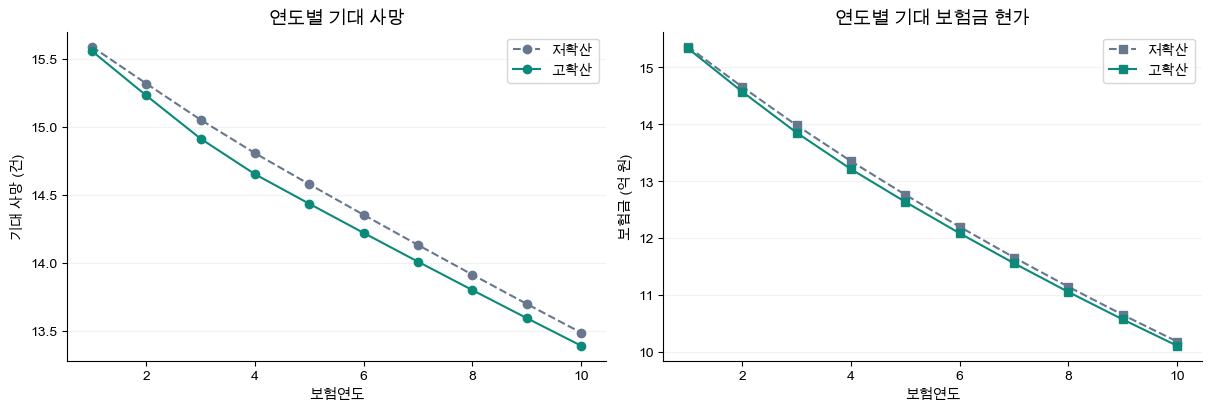

In [7]:
# 그래프 2. 기대 사망과 기대 보험금을 저확산/고확산 두 경로로 비교
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
x=annual['연도']
for name,col,line in [('저확산','저확산_사망',GREY),('고확산','고확산_사망',GREEN)]:
 ax[0].plot(x,annual[col],label=name,color=line,ls='--' if name=='저확산' else '-',marker='o')
for name,col,line in [('저확산','저확산_PV억원',GREY),('고확산','고확산_PV억원',GREEN)]:
 ax[1].plot(x,annual[col],label=name,color=line,ls='--' if name=='저확산' else '-',marker='s')
ax[0].set(title='연도별 기대 사망',xlabel='보험연도',ylabel='기대 사망 (건)')
ax[1].set(title='연도별 기대 보험금 현가',xlabel='보험연도',ylabel='보험금 (억 원)')
for a in ax:a.legend();a.grid(axis='y',alpha=.16)
plt.show()

저확산과 고확산의 차이는 전체 가입자에게 일괄 적용되지 않는다. 각 시점에 치료 효과기간 안에 있는 시작경험자에게만 HR 0.81이 적용된다.


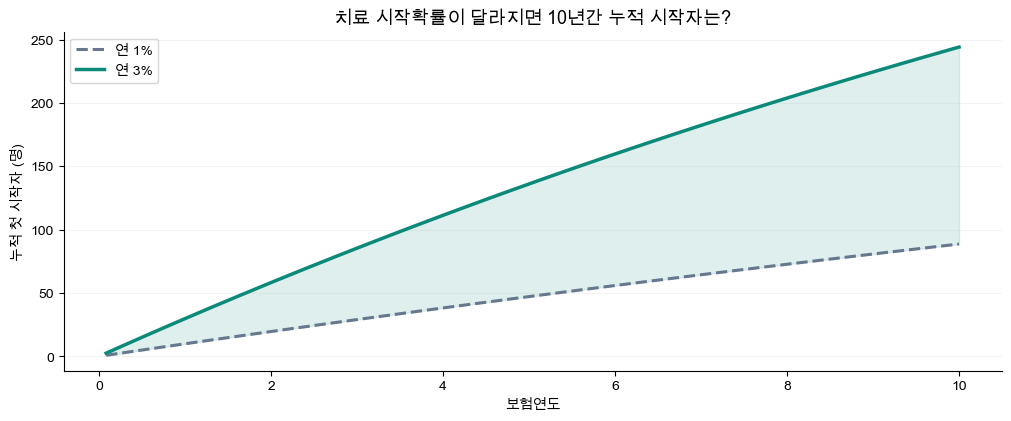

In [8]:
# 그래프 3. 누적 치료 시작자와 고확산으로 더 시작한 사람
fig,ax=plt.subplots(figsize=(10,4.1),layout='constrained')
ax.plot(L['월']/12,L['누적_시작'],color=GREY,ls='--',lw=2.2,label='연 1%')
ax.plot(H['월']/12,H['누적_시작'],color=GREEN,lw=2.5,label='연 3%')
ax.fill_between(L['월']/12,L['누적_시작'],H['누적_시작'],color=GREEN,alpha=.13)
ax.set(title='치료 시작확률이 달라지면 10년간 누적 시작자는?',xlabel='보험연도',ylabel='누적 첫 시작자 (명)')
ax.legend();ax.grid(axis='y',alpha=.15)
plt.show()

연 시작확률의 분모는 매월 남아 있는 생존·미시작자다. 따라서 연 3% 경로에서도 매년 동일한 인원 30명이 새로 시작하는 구조는 아니다.


## 6. 국내 규모 환산

국민건강영양조사 2024의 기존 재집계에서 45~79세 일반인구 중 SELECT 유사 대리집단의 가중 비율은 약 **0.25675%**였다.

| 항목 | 기존 재집계 값 |
|---|---:|
| 45~79세 판별가능 일반인구 가중합 | 약 2,424만 명 |
| SELECT 유사 조건 가중합 | 약 6.22만 명 |
| 조건 해당 원표본 | 11명 |
| SELECT 유사 대리집단 비율 | 약 0.25675% |
| 가상 기존 가입자 10만 명 적용 시 후보 | 약 257명 |

아래 환산은 일반인구 비율이 보험가입자에게도 같고, 후보 전원이 동일한 사망강도와 시작경로를 가진다는 조건부 계산이다. 실제 포트폴리오로 확장하려면 담보 보유·유효 비중과 인수·병력 구성이 추가로 필요하다.

$$
\text{전체 기대 사망보험금 변화}
=\text{전체 기존계약}
\times\text{SELECT 유사 비중}
\times\text{담보 보유·유효 비중}
\times\text{대상 계약 1건당 변화}
$$

**출처:** 국민건강영양조사 2024. https://knhanes.kdca.go.kr/


In [9]:
# 국내 가상 10만 명 환산. 주 계산과 다른 분모; 일반인구 가중비율을 보험 가입자에 옮긴다는 가정.
KNHANES_SHARE=62238.568315/24240644.983522
N_100K_SELECT=100_000*KNHANES_SHARE
korea=contrast(n=N_100K_SELECT)
display(pd.DataFrame([
 {'분모':'SELECT 유사 가상 가입자 1,000명','효과 적용 후보(명)':1000,'추가 시작(명)':base['delta_starts'],'기대 사망 감소(건)':base['avoided_deaths'],'PV 감소(만 원)':base['pv_saving']/1e4},
 {'분모':'45~79세 가상 가입자 10만명 / 인구비중 이전','효과 적용 후보(명)':N_100K_SELECT,'추가 시작(명)':korea['delta_starts'],'기대 사망 감소(건)':korea['avoided_deaths'],'PV 감소(만 원)':korea['pv_saving']/1e4}]).round(3))
print('주의: 국내 보험사 관측값이 아닌 조건부 규모 환산입니다.')

,분모,효과 적용 후보(명),추가 시작(명),기대 사망 감소(건),PV 감소(만 원)
0,"SELECT 유사 가상 가입자 1,000명",1000.000,155.442,1.128,9696.186
1,45~79세 가상 가입자 10만명 / 인구비중 이전,256.753,39.910,0.290,2489.524


주의: 국내 보험사 관측값이 아닌 조건부 규모 환산입니다.


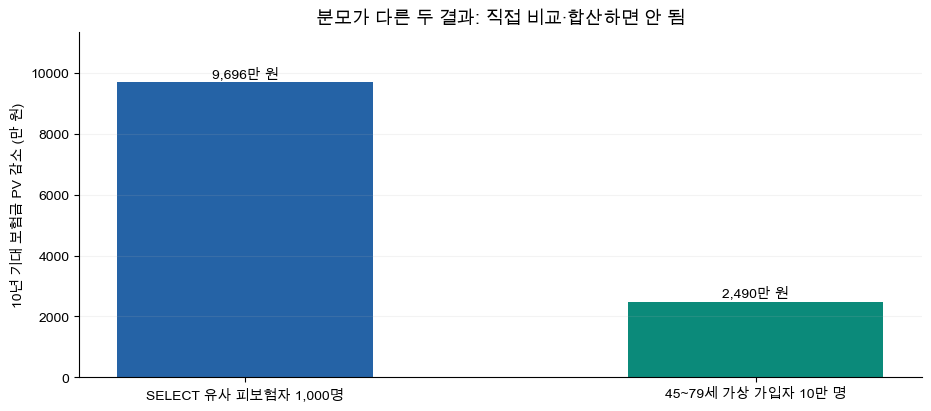

In [10]:
# 그래프 7. 분모가 다른 수치는 더해서는 안 된다
fig,ax=plt.subplots(figsize=(9.2,4),layout='constrained')
vals=[base['pv_saving']/1e4,korea['pv_saving']/1e4]
bars=ax.bar(['SELECT 유사 피보험자 1,000명','45~79세 가상 가입자 10만 명'],vals,color=[BLUE,GREEN],width=.5)
for b,v in zip(bars,vals):ax.text(b.get_x()+b.get_width()/2,v+150,f'{v:,.0f}만 원',ha='center',weight='bold')
ax.set(title='분모가 다른 두 결과: 직접 비교·합산하면 안 됨',ylabel='10년 기대 보험금 PV 감소 (만 원)',ylim=(0,max(vals)*1.17))
ax.grid(axis='y',alpha=.15)
plt.show()

## 7. 민감도 분석

기준은 HR 0.81, 효과기간 3년, 기초 사망강도 1배, 할인율 3%, 시장 저확산 1%와 고확산 3%다. 사망 HR, 효과기간, 기초 사망강도, 할인율과 고확산 시작확률을 한 번에 하나씩 변경한다.


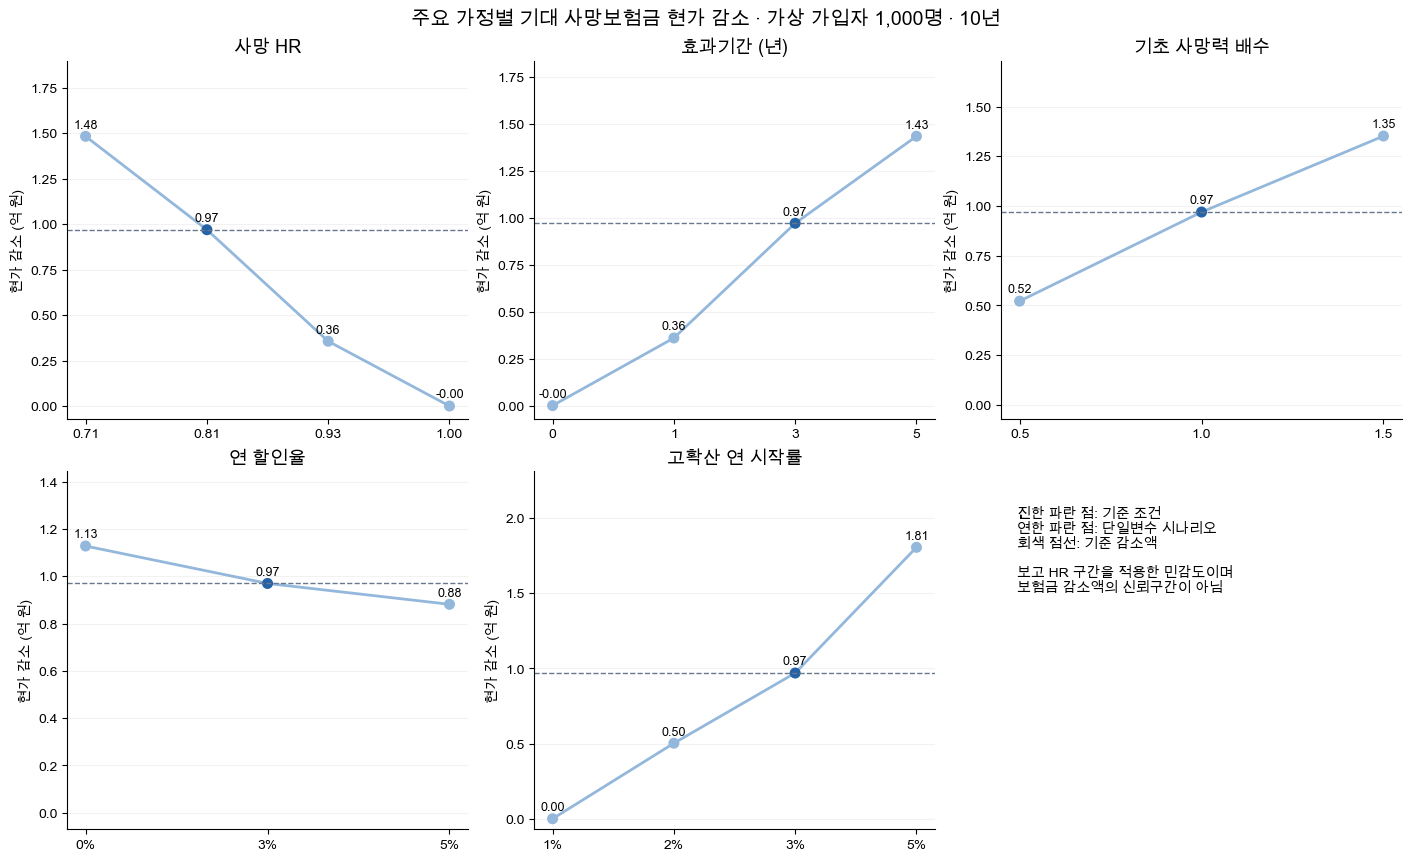

,조건,값,10년_현가감소억원
0,사망 HR,0.71,1.483245e+00
1,사망 HR,0.81,9.696186e-01
2,사망 HR,0.93,3.562751e-01
3,사망 HR,1.00,-7.629395e-14
4,효과기간 (년),0,-7.629395e-14
5,효과기간 (년),1,3.596789e-01
6,효과기간 (년),3,9.696186e-01
7,효과기간 (년),5,1.432413e+00
8,기초 사망력 배수,0.5,5.216415e-01
9,기초 사망력 배수,1.0,9.696186e-01


In [11]:
cases=[
('사망 HR',[.71,.81,.93,1],lambda x:{'hr':x},lambda x:f'{x:.2f}'),
('효과기간 (년)',[0,1,3,5],lambda x:{'effect_m':int(x*12)},lambda x:f'{x}'),
('기초 사망력 배수',[.5,1,1.5],lambda x:{'mu':MU*x},lambda x:f'{x:.1f}'),
('연 할인율',[0,.03,.05],lambda x:{'discount':x},lambda x:f'{x*100:.0f}%'),
('고확산 연 시작률',[.01,.02,.03,.05],lambda x:{'high':x},lambda x:f'{x*100:.0f}%')]
baseline_values = {
    '사망 HR': TRIAL_HR,
    '효과기간 (년)': EFFECT_MONTHS / 12,
    '기초 사망력 배수': 1.0,
    '연 할인율': ANNUAL_DISCOUNT,
    '고확산 연 시작률': HIGH_START,
}
fig,axs=plt.subplots(2,3,figsize=(14,8.5),layout='constrained')
rows=[]
for ax,(title,vals,fun,fmt) in zip(axs.flat,cases):
    ys=[]
    for v in vals:
        r=contrast(**fun(v))
        ys.append(r['pv_saving']/1e8)
        rows.append({'조건':title,'값':fmt(v),'10년_현가감소억원':r['pv_saving']/1e8})
    x=np.arange(len(vals))
    ax.plot(x,ys,color='#93B8DC',lw=2,zorder=1)
    point_colors=[BLUE if math.isclose(float(v),float(baseline_values[title]),rel_tol=0,abs_tol=1e-12)
                  else '#93B8DC' for v in vals]
    ax.scatter(x,ys,c=point_colors,s=48,zorder=2)
    ax.axhline(base['pv_saving']/1e8,color=GREY,ls='--',lw=1)
    for xi,y in zip(x,ys):
        ax.annotate(f'{y:.2f}',(xi,y),xytext=(0,6),textcoords='offset points',
                    ha='center',fontsize=9)
    ax.set(title=title,ylabel='현가 감소 (억 원)',xticks=x,
           xticklabels=[fmt(v) for v in vals],ylim=(-.07,max(ys)*1.28))
    ax.grid(axis='y',alpha=.16)
axs[1,2].axis('off')
axs[1,2].text(.04,.9,'진한 파란 점: 기준 조건\n연한 파란 점: 단일변수 시나리오\n회색 점선: 기준 감소액\n\n보고 HR 구간을 적용한 민감도이며\n보험금 감소액의 신뢰구간이 아님',va='top')
fig.suptitle(
    f'주요 가정별 기대 사망보험금 현가 감소 · 가상 가입자 {COHORT:,}명 · {N_YEARS}년',
    fontsize=14,weight='bold'
)
plt.show()
sens=pd.DataFrame(rows)
display(sens)


- HR=1이거나 효과기간이 0이면 기대 사망보험금 감소는 0원이다.
- 효과기간과 기초 사망강도가 커질수록 감소액은 커진다.
- 할인율이 높아지면 미래 보험금의 현재가치는 작아진다.
- 저확산과 고확산 시작확률이 같으면 비교 경로가 같아져 차이는 0이다.
- HR 1.00~0.71 적용 결과인 0~1.48억 원은 단일변수 시나리오 범위이며 보험금 감소액의 95% 신뢰구간이 아니다.


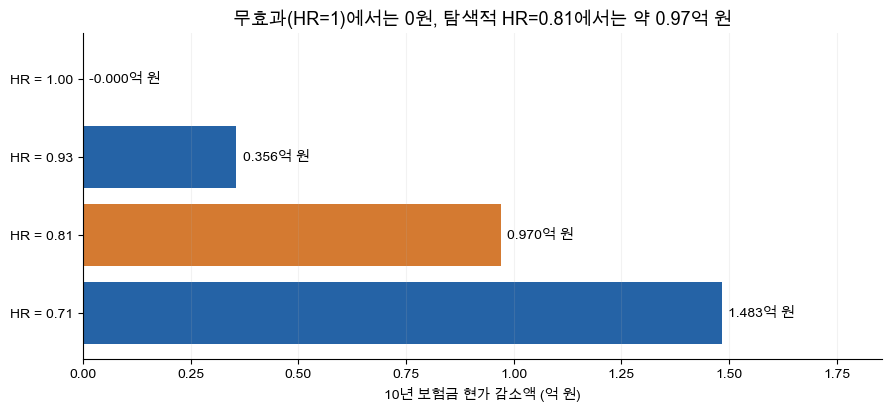

In [12]:
# 그래프 5. HR 무효과를 포함한 비교
hr_list=[1,.93,.81,.71]
res=[contrast(hr=h)['pv_saving']/1e8 for h in hr_list]
fig,ax=plt.subplots(figsize=(8.8,4),layout='constrained')
b=ax.barh([f'HR = {h:.2f}' for h in hr_list],res,color=[GREY,BLUE,ORANGE,BLUE])
ax.invert_yaxis()
for bar,v in zip(b,res):ax.text(v+.015,bar.get_y()+bar.get_height()/2,f'{v:.3f}억 원',va='center')
ax.set(xlim=(0,max(res)*1.25),xlabel='10년 보험금 현가 감소액 (억 원)',title='무효과(HR=1)에서는 0원, 탐색적 HR=0.81에서는 약 0.97억 원')
ax.grid(axis='x',alpha=.16)
plt.show()

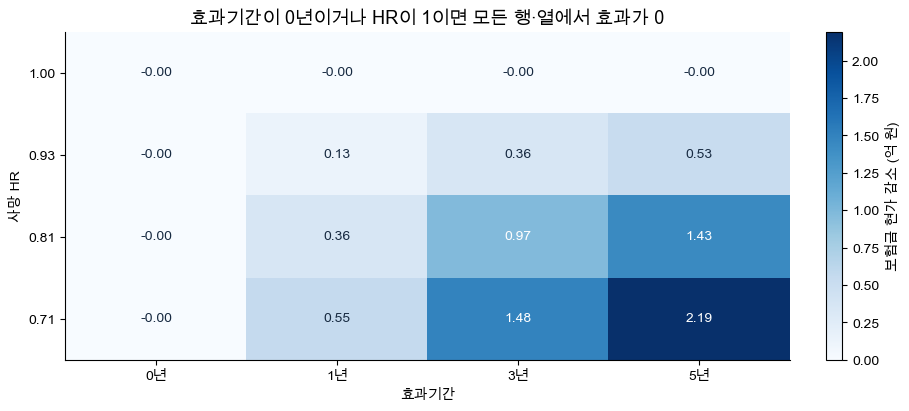

In [13]:
# 그래프 6. HR과 효과기간을 동시에 바꾸면 어떻게 되나? (가정 조합 점검, 확률적 CI 아님)
hrs=[1,.93,.81,.71]; yrs=[0,1,3,5]
heat=np.array([[contrast(hr=h,effect_m=y*12)['pv_saving']/1e8 for y in yrs] for h in hrs])
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
im=ax.imshow(heat,cmap='Blues',vmin=0,vmax=heat.max(),aspect='auto')
ax.set(xticks=range(4),xticklabels=[f'{k}년' for k in yrs],yticks=range(4),yticklabels=[f'{h:.2f}' for h in hrs],xlabel='효과기간',ylabel='사망 HR',title='효과기간이 0년이거나 HR이 1이면 모든 행·열에서 효과가 0')
for i in range(4):
 for j in range(4):ax.text(j,i,f'{heat[i,j]:.2f}',ha='center',va='center',color='white' if heat[i,j]>.9 else '#172A41')
fig.colorbar(im,ax=ax,label='보험금 현가 감소 (억 원)')
plt.show()

## 8. 결과 해석과 한계

| 구분 | 해석 |
|---|---|
| 무엇을 보여주나 | 시장 저확산에서 고확산으로 이동할 때 기존 생명보험 정기 사망보장의 기대 급부 변화 |
| 무엇을 바로 말할 수 없나 | 약제비 특약 자체가 만든 감소액, 실제 국내 보험사의 절감액·순이익 |
| 임상효과 | SELECT 전체 사망 HR은 탐색적 결과이며 국내 보험가입자 효과로 직접 검증되지 않음 |
| 기초위험 | 위약군 기간 평균 사망강도를 10년간 일정하게 외삽해 연령 증가와 장기 변화가 빠짐 |
| 시작·효과기간 | 연 1%·3%와 최초 시작 후 36개월 효과는 연구팀의 시나리오 가정 |
| 계약·상태 | 해지, 약물 중단·재개, 경쟁사건과 계약조건 변경을 반영하지 않음 |
| 국내 환산 | 조건 해당 원표본이 11명이고 보험가입자 구성·담보 보유율 자료가 없음 |

현재 결과는 가정을 공개한 조건부 시나리오 분석으로 사용할 수 있다. 실제 포트폴리오 영향으로 확장하려면 국내 연령·성별·병력별 사망위험, 인수조건, 담보 보유율과 유지율이 추가로 필요하다.


## 9. 결론과 공통모형 연결

1. 기준 가정에서 시장 저확산에서 고확산으로 이동하면 10년 기대 사망은 약 **1.1279건**, 기대 사망보험금 현가는 약 **9,696만 원 감소**한다.
2. 사망효과가 없는 HR=1에서는 감소액이 0원이며, 결과 크기는 치료효과·기초위험·시작경로·효과기간에 좌우된다.
3. 이 결과는 시장 전체 확산에 따른 기존 사망보장 영향이며 약제비 특약의 귀속효과가 아니다.
4. 특약 귀속효과를 계산할 때에는 `특약 없음 A → 특약 있음 A+B`의 시작경로 차이를 사용한다.

공통모형에서는 대상 집단, 시작경로, 시간축, 할인율과 담보 보유율을 통일한 뒤 다음 구조로 결합한다.

$$
\text{보험사 순영향}
=\text{특약 손익}
+\text{사망보험금 감소}
+\text{심혈관 사건급부 감소}
-\text{담낭수술 급부 증가}
$$

현재 노트북은 이 가운데 시장 확산에 따른 **기대 사망보험금 감소**만 계산한다.


## 10. 계산 검증

| 검증 항목 | 확인 내용 |
|---|---|
| 동일 시작률 | 저확산과 고확산이 같으면 차이 0 |
| 무효과 조건 | HR=1 또는 효과기간=0이면 차이 0 |
| 인원 보존 | 전월 생존자 = 당월 사망자 + 월말 생존자 |
| 할인 | 할인율 0이면 현재가치 차이와 명목 차이 일치 |
| 선형성 | 가입자 2배이면 기대 보험금 차이 2배 |
| 기준 재현 | 기대 사망 감소와 9,696만 원 결과 및 연도별 합계 일치 |

검증은 계산 구조의 일관성과 기준 결과 재현을 확인한다.


In [14]:
checks={
'저확산=고확산이면 차이 0':abs(contrast(high=.01)['pv_saving'])<1e-5,
'HR=1이면 차이 0':abs(contrast(hr=1)['pv_saving'])<1e-5,
'효과기간 0이면 차이 0':abs(contrast(effect_m=0)['pv_saving'])<1e-5,
'할인 0이면 명목과 현가 동일':abs(contrast(discount=0)['pv_saving']-base['nominal_saving'])<1e-5,
'규모 2배이면 차이 2배':abs(contrast(n=2000)['pv_saving']/base['pv_saving']-2)<1e-9,
'월 인원 보존':abs(base['low']['deaths']+base['low']['survivors']-1000)<1e-7,
'원형 기준 9,696만원 재현':abs(base['pv_saving']-96961864)<5,
'연도별 현가 합계 일치':abs(annual['연간_감소액억원'].sum()*1e8-base['pv_saving'])<1e-5}
assert all(checks.values())
display(pd.DataFrame([{'점검':k,'결과':'통과' if v else '실패'} for k,v in checks.items()]))

,점검,결과
0,저확산=고확산이면 차이 0,통과
1,HR=1이면 차이 0,통과
2,효과기간 0이면 차이 0,통과
3,할인 0이면 명목과 현가 동일,통과
4,규모 2배이면 차이 2배,통과
5,월 인원 보존,통과
6,"원형 기준 9,696만원 재현",통과
7,연도별 현가 합계 일치,통과


## 부록 · 출처와 단위

- [SELECT 논문](https://doi.org/10.1056/NEJMoa2307563) — 임상 대상과 전체 사망 HR
- [SELECT 검토자료 Table 19](https://www.ncbi.nlm.nih.gov/books/NBK619926/table/tr8269868382084182_ch01_t19/?report=objectonly) — 사망 건수와 관찰 인년
- [SELECT 사망 세부분석](https://pubmed.ncbi.nlm.nih.gov/39217559/) — 보조 임상정보
- [Nanna et al. 2025](https://pmc.ncbi.nlm.nih.gov/articles/PMC12046440/) — 임상효과의 장기 집단 추계 방법론 참고
- [CBO 2024](https://www.cbo.gov/publication/60816) — 해외 비만치료제 시작률 전망 참고
- [국민건강영양조사](https://knhanes.kdca.go.kr/) — 국내 SELECT 유사 대리집단 기존 재집계
- [2024 국내 완전생명표](https://mods.go.kr/board.es?act=view&bid=208&list_no=439533&mid=a10301010000) — 일반인구 대조 자료이며 기준위험에는 미사용

기대 사망은 코호트의 확률적 기대값이므로 소수 건이 가능하다. 보험금은 원 단위로 계산하고 표·본문에서는 억 원 또는 만 원으로 표시한다. 현재가치는 각 월의 기대 보험금을 연 3%로 할인한 합계다.
